# 06 - Explainability, reliability scorecard and decision rules (DataCo, shipped orders)
1. **Shipping-mode scorecard.** Reliability against the promise (late rate) *and* in absolute terms (days, spread), with 95% confidence intervals, plus a cost-side view.
2. **Region reliability**, after controlling for the shipping-mode mix.
3. **SHAP** (TreeSHAP values from LightGBM) for the final late-delivery model.
4. **Decision rules evaluated on the test split:** how many late orders do they catch, and what do false alarms cost?

Run notebooks 04 and 05 first: this notebook loads `models/late_delivery_lgbm.joblib` and `models/eta_lgbm.joblib`.

In [1]:
import sys; sys.path.append("..")
import yaml, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from src.data.load import load_dataco
from src.data.clean import clean_dataco
from src.features.build_features import DATACO_TARGET_CLF, DATACO_TARGET_REG, build_dataco_features, shipped_only, time_split
from src.models.train_risk import fit_calibrator, rule_key
from src.decision.rules import recommend

cfg = yaml.safe_load(open("../config.yaml")); SEED = cfg["seed"]
tables = Path("../reports/tables"); figs = Path("../" + cfg["paths"]["figures"])
tables.mkdir(parents=True, exist_ok=True); figs.mkdir(parents=True, exist_ok=True)
Y, YR, PROMISE, MODE = DATACO_TARGET_CLF, DATACO_TARGET_REG, "Days for shipment (scheduled)", "Shipping Mode"

full = build_dataco_features(clean_dataco(load_dataco("../" + cfg["paths"]["dataco"])))
data = shipped_only(full)
data["year"] = data["order date (DateOrders)"].dt.year

def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float); p = k / n
    d = 1 + z * z / n; c = p + z * z / (2 * n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d
len(data)

172765

## 1. Shipping-mode scorecard
`late_rate` measures reliability **against the promise**. `mean_real_days` and `std_real_days` measure it **in absolute terms**.
Cost side: the data has no shipping-cost column, so profit per order is used as the cost-side proxy (what the business keeps).

In [2]:
g = data.groupby(MODE)
sc = pd.DataFrame({"orders": g.size(), "promised_days": g[PROMISE].mean(), "mean_real_days": g[YR].mean(),
                   "std_real_days": g[YR].std(), "late_rate": g[Y].mean()})
sc["late_ci_low"], sc["late_ci_high"] = wilson(g[Y].sum().values, sc["orders"].values)
late = data[data[Y] == 1].assign(days_late=lambda d: d[YR] - d[PROMISE])
sc["avg_days_late_if_late"] = late.groupby(MODE)["days_late"].mean()
sc["profit_per_order"] = g["Order Profit Per Order"].mean()
sc["sales_per_item"] = g["Sales"].mean()
sc["profit_ci95"] = 1.96 * g["Order Profit Per Order"].std() / np.sqrt(sc["orders"])   # +/- around profit_per_order
sc = sc.sort_values("late_rate").round(3); sc.to_csv(tables / "scorecard_shipping_mode.csv"); sc

,orders,promised_days,mean_real_days,std_real_days,late_rate,late_ci_low,late_ci_high,avg_days_late_if_late,profit_per_order,sales_per_item,profit_ci95
Shipping Mode,,,,,,,,,,,
Standard Class,103153,4.0,3.994,1.419,0.398,0.395,0.401,1.507,22.033,204.462,0.639
Same Day,9293,0.0,0.479,0.500,0.479,0.469,0.489,1.000,20.896,199.599,2.010
Second Class,33806,2.0,3.993,1.414,0.798,0.794,0.803,2.497,21.383,202.942,1.147
First Class,26513,1.0,2.000,0.000,1.000,1.000,1.000,1.000,23.256,203.978,1.210


### How likely is a delivery within d days, for each option?
This is the table a customer-facing "delivery confidence" feature would use. Same Day is split at the noon order cutoff. Values are the share of shipped orders delivered within d days.

In [3]:
keyed = data.assign(option=rule_key(data))
within = pd.DataFrame({f"within {d} days": keyed.groupby("option")[YR].apply(lambda s, d=d: (s <= d).mean()) for d in range(0, 7)}).round(3)
within.insert(0, "orders", keyed.groupby("option").size())
within.to_csv(tables / "arrival_within_days.csv"); within

,orders,within 0 days,within 1 days,within 2 days,within 3 days,within 4 days,within 5 days,within 6 days
option,,,,,,,,
First Class,26513,0.0,0.0,1.000,1.000,1.000,1.000,1.0
Same Day (before noon),4839,1.0,1.0,1.000,1.000,1.000,1.000,1.0
Same Day (from noon),4454,0.0,1.0,1.000,1.000,1.000,1.000,1.0
Second Class,33806,0.0,0.0,0.202,0.402,0.602,0.802,1.0
Standard Class,103153,0.0,0.0,0.202,0.403,0.602,0.798,1.0


Late rate by year (2018 = January only):


year,2015,2016,2017,2018
Shipping Mode,,,,
First Class,1.000,1.000,1.000,1.000
Same Day,0.471,0.448,0.528,0.446
Second Class,0.803,0.798,0.793,0.807
Standard Class,0.397,0.401,0.394,0.408


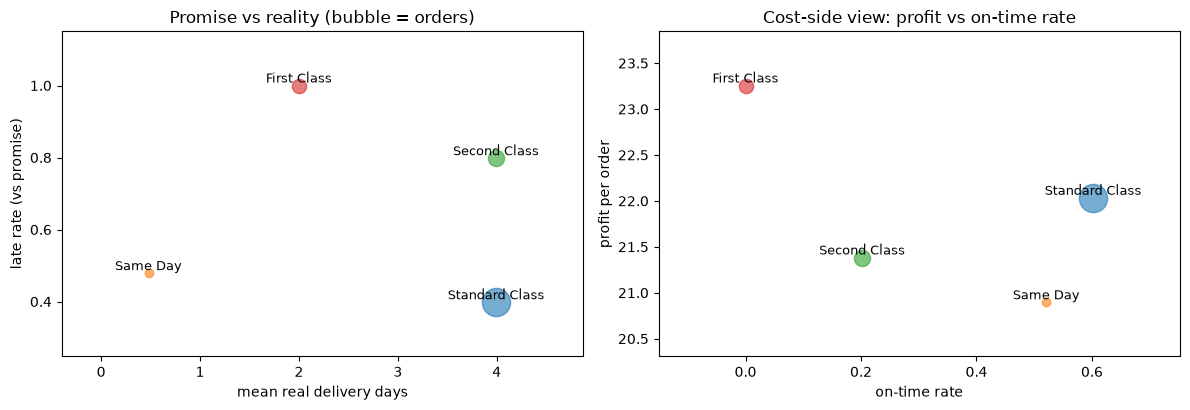

In [4]:
print("Late rate by year (2018 = January only):")
display(data.pivot_table(index=MODE, columns="year", values=Y, aggfunc="mean").round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for m, r in sc.iterrows():
    ax[0].scatter(r["mean_real_days"], r["late_rate"], s=r["orders"] / 250, alpha=.6); ax[0].annotate(m, (r["mean_real_days"], r["late_rate"]), ha="center", va="bottom", fontsize=9)
    ax[1].scatter(1 - r["late_rate"], r["profit_per_order"], s=r["orders"] / 250, alpha=.6); ax[1].annotate(m, (1 - r["late_rate"], r["profit_per_order"]), ha="center", va="bottom", fontsize=9)
ax[0].set(xlabel="mean real delivery days", ylabel="late rate (vs promise)", title="Promise vs reality (bubble = orders)")
ax[1].set(xlabel="on-time rate", ylabel="profit per order", title="Cost-side view: profit vs on-time rate")
for a in ax: a.margins(.25)
fig.tight_layout(); fig.savefig(figs / "scorecard_modes.png", dpi=150); plt.show()

**How to read this.** Compare Second Class and Standard Class: if their `mean_real_days` and `std_real_days` are about the same but their `late_rate` differs a lot, the
late rate reflects how aggressive the *promise* is, not how fast or steady the delivery is. First Class has `std_real_days = 0`: perfectly steady, and always one day over its promise.

## 2. Region reliability, controlling for shipping mode
Expected late rate for a region = what its mode mix would give if every mode behaved as it does overall. z compares observed with expected.

3 of 21 regions have |z| > 1.96 (about 1.1 expected by chance alone)


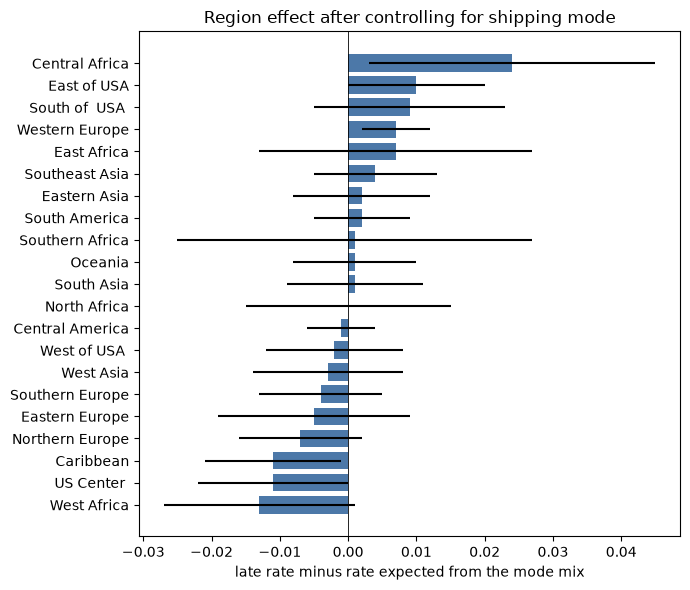

,orders,observed,expected,diff,ci,z
Order Region,,,,,,
West Africa,3571,0.547,0.559,-0.013,0.014,-1.707
US Center,5653,0.575,0.586,-0.011,0.011,-1.887
Caribbean,7951,0.555,0.566,-0.011,0.010,-2.155
Northern Europe,9408,0.562,0.569,-0.007,0.009,-1.489
Eastern Europe,3785,0.576,0.582,-0.005,0.014,-0.785
Southern Europe,9030,0.568,0.572,-0.004,0.009,-0.957
West Asia,5746,0.578,0.582,-0.003,0.011,-0.605
West of USA,7595,0.568,0.570,-0.002,0.010,-0.348
Central America,27174,0.571,0.572,-0.001,0.005,-0.327


In [5]:
data["exp_p"] = data[MODE].map(data.groupby(MODE)[Y].mean())
r = data.groupby("Order Region").agg(orders=(Y, "size"), observed=(Y, "mean"), expected=("exp_p", "mean"),
                                     var=("exp_p", lambda s: (s * (1 - s)).sum()))
r["diff"] = r["observed"] - r["expected"]
r["ci"] = 1.96 * np.sqrt(r["var"]) / r["orders"]
r["z"] = r["diff"] * r["orders"] / np.sqrt(r["var"])
r = r[r["orders"] >= 1000].sort_values("diff").drop(columns="var").round(3)
r.to_csv(tables / "region_reliability.csv")
print(f"{(r['z'].abs() > 1.96).sum()} of {len(r)} regions have |z| > 1.96 (about {0.05 * len(r):.1f} expected by chance alone)")
fig, ax = plt.subplots(figsize=(7, 6)); ax.barh(r.index, r["diff"], xerr=r["ci"], color="#4C78A8"); ax.axvline(0, color="k", lw=.6)
ax.set(xlabel="late rate minus rate expected from the mode mix", title="Region effect after controlling for shipping mode"); fig.tight_layout()
fig.savefig(figs / "region_reliability.png", dpi=150); plt.show()
r

## 3. SHAP for the final late-delivery model
TreeSHAP values come from LightGBM itself (`pred_contrib=True`), computed on 3,000 test orders.

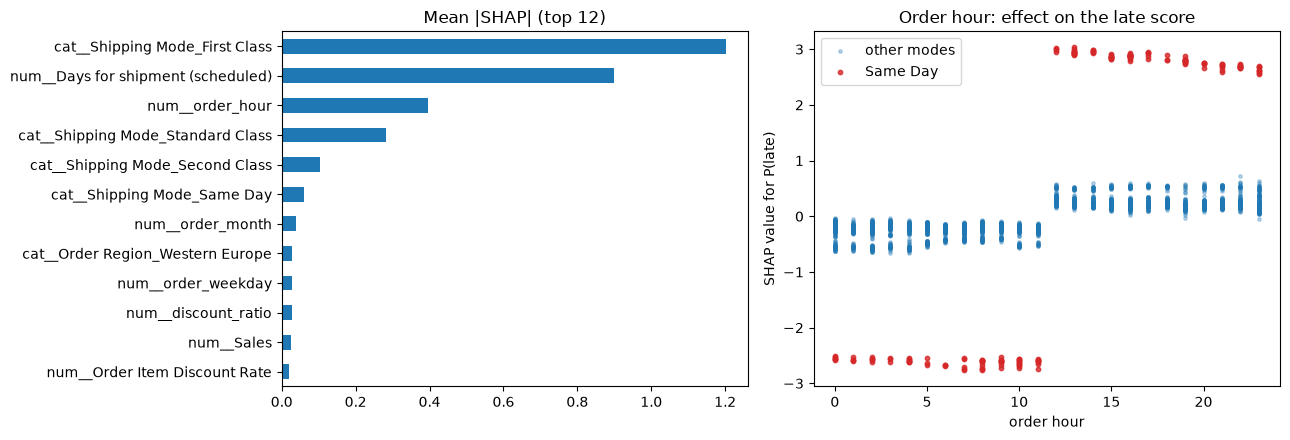

cat__Shipping Mode_First Class        0.362
num__Days for shipment (scheduled)    0.271
num__order_hour                       0.119
cat__Shipping Mode_Standard Class     0.085
cat__Shipping Mode_Second Class       0.031
cat__Shipping Mode_Same Day           0.018
num__order_month                      0.011
cat__Order Region_Western Europe      0.009
num__order_weekday                    0.009
num__discount_ratio                   0.008
dtype: float64

In [6]:
bundle = joblib.load("../" + cfg["paths"]["models"] + "/late_delivery_lgbm.joblib")
model, FEATS = bundle["model"], bundle["features"]
train, val, test = time_split(data, cfg["split"]["train"], cfg["split"]["val"])
sample = test.sample(min(3000, len(test)), random_state=SEED)
prep, clf = model.named_steps["prep"], model.named_steps["clf"]
X = prep.transform(sample[FEATS]); X = X.toarray() if hasattr(X, "toarray") else np.asarray(X)
names = np.array(prep.get_feature_names_out())
sv = clf.booster_.predict(X, pred_contrib=True)[:, :-1]            # last column is the base value
imp = pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
imp.head(12)[::-1].plot.barh(ax=ax[0], title="Mean |SHAP| (top 12)")
i = int(np.where(names == "num__order_hour")[0][0]); sd = (sample[MODE] == "Same Day").to_numpy()
ax[1].scatter(X[~sd, i], sv[~sd, i], s=6, alpha=.3, label="other modes"); ax[1].scatter(X[sd, i], sv[sd, i], s=10, alpha=.8, color="C3", label="Same Day")
ax[1].set(xlabel="order hour", ylabel="SHAP value for P(late)", title="Order hour: effect on the late score"); ax[1].legend()
fig.tight_layout(); fig.savefig(figs / "shap_late_delivery.png", dpi=150); plt.show()
(imp / imp.sum()).head(10).round(3)

**How to read this.** Shipping mode and promised days should dominate. The order-hour panel should show a step at 12:00 only for Same Day orders (red); for other modes the hour should have
no effect. That matches the 5-row lookup table: SHAP is confirming the rule, not finding anything new.

## 4. Evaluating the decision rules on the test split
Calibrated P(late) comes from the validation split. The interval width comes from the per-mode conformal half-widths of the ETA model (width = 2 x half-width). Order value = `Sales`.

In [7]:
eta = joblib.load("../" + cfg["paths"]["models"] + "/eta_lgbm.joblib"); hw = eta["conformal_halfwidths"]
cal = fit_calibrator(model.predict_proba(val[FEATS])[:, 1], val[Y])
test = test.assign(p_late=cal.predict(model.predict_proba(test[FEATS])[:, 1]))
test["interval_days"] = [2 * hw.get(m, hw["__all__"]) for m in test[MODE]]
rules = cfg["rules"]
acts = [recommend(p, v, w, rules) for p, v, w in zip(test["p_late"], test["Sales"], test["interval_days"])]
test["primary"] = [a[0].split(":")[0] for a in acts]
test["tier_flag"] = [any(x.startswith(("RE-PROMISE", "ALERT")) for x in a) for a in acts]
test["warn_flag"] = [any(x.startswith("WARN") for x in a) for a in acts]

t = test.groupby("primary")[Y].agg(orders="size", late_rate="mean", late_orders="sum")
t["share_of_orders"] = t["orders"] / len(test); t["share_of_late_orders"] = t["late_orders"] / test[Y].sum()
print(f"base late rate on test = {test[Y].mean():.3f}; thresholds: {rules}")
display(t.round(3))

def coverage(mask, name):
    tp = int((mask & (test[Y] == 1)).sum()); fp = int((mask & (test[Y] == 0)).sum())
    return {"rule": name, "orders_flagged": int(mask.sum()), "share_of_orders": round(mask.mean(), 3),
            "precision": round(tp / max(mask.sum(), 1), 3), "recall": round(tp / test[Y].sum(), 3),
            "false_alarms_per_late_order_caught": round(fp / max(tp, 1), 3)}
cov = pd.DataFrame([coverage(test["tier_flag"].to_numpy(), "High-tier alert / re-promise"),
                    coverage(test["warn_flag"].to_numpy(), "Warn customer (wide interval)"),
                    coverage((test["tier_flag"] | test["warn_flag"]).to_numpy(), "Any action")]).set_index("rule")
cov.to_csv(tables / "decision_rules_evaluation.csv"); cov

base late rate on test = 0.576; thresholds: {'late_prob_expedite': 0.7, 'high_value_order': 200.0, 'eta_interval_wide_days': 3.0, 'risk_alert_level': 'High', 'tier_high_prob': 0.7, 'tier_low_prob': 0.2}


,orders,late_rate,late_orders,share_of_orders,share_of_late_orders
primary,,,,,
ALERT,5240,0.896,4695,0.202,0.314
NO ACTION,635,0.000,0,0.025,0.000
RE-PROMISE,4459,0.901,4019,0.172,0.269
WARN CUSTOMER,15581,0.399,6216,0.601,0.416


,orders_flagged,share_of_orders,precision,recall,false_alarms_per_late_order_caught
rule,,,,,
High-tier alert / re-promise,9699,0.374,0.898,0.584,0.113
Warn customer (wide interval),20566,0.794,0.497,0.684,1.013
Any action,25280,0.975,0.591,1.000,0.693


**How to read the last column.** `false_alarms_per_late_order_caught` is the break-even: the rule pays off only if preventing or pre-empting one late order is worth more than that many false alarms.
If the wide-interval rule fires on most orders, it carries little information. Delivery time inside Second and Standard Class is random, so the honest message is "2 to 6 days", not a sharper date.
Tune `eta_interval_wide_days`, `tier_high_prob` and `tier_low_prob` in `config.yaml`, then rerun this section.

## Results to copy into `reports/experiment_log.md`
Scorecard: late rate (95% CI) by mode: ...
Region: ... of ... regions differ from the mode-mix expectation (about ... expected by chance)
Rules: High-tier alert catches ...% of late orders at precision ...; false alarms per late order caught ...

## Takeaways (fill in)
1. 
2. 
3. 